In [ ]:
# Cell 1: Install required libraries and imports
!pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn tensorflow plotly

# Data manipulation and analysis
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc,
                             roc_auc_score, precision_recall_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Handle imbalanced data
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Cell 2: Load dataset (Telco Customer Churn)
import kagglehub

# Download the dataset
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path to dataset files:", path)

# Load the data
df = pd.read_csv(f"{path}/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(f"Dataset shape: {df.shape}")
print(f"\nFirst 5 rows:")
display(df.head())
print(f"\nDataset info:")
display(df.info())

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-

None

EXPLORATORY DATA ANALYSIS

1. Missing Values:


,Missing Count,Percentage



2. Basic Statistics for Numerical Columns:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



3. Target Variable Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Rate: 26.54%


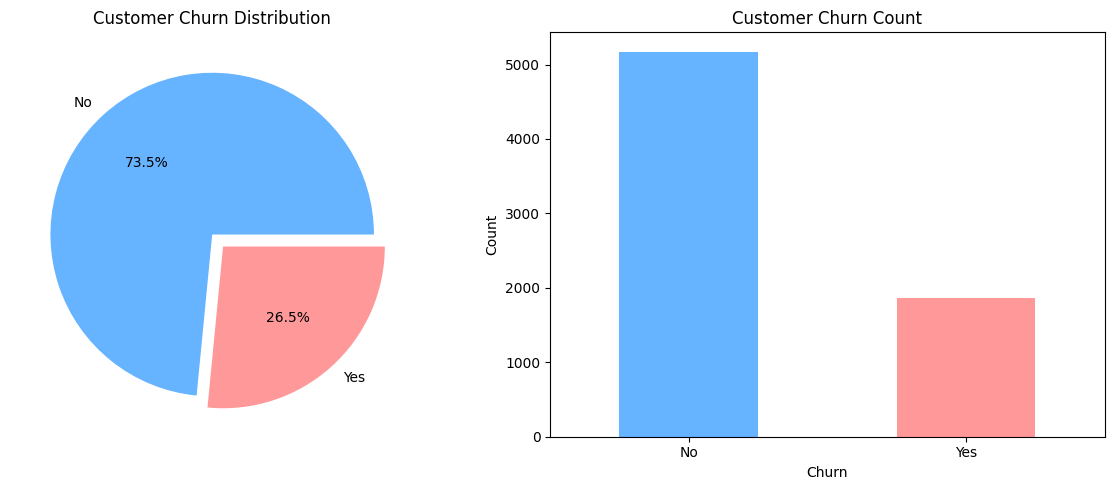

In [ ]:
# Cell 3: Basic EDA
print("="*50)
print("EXPLORATORY DATA ANALYSIS")
print("="*50)

# Check for missing values
print("\n1. Missing Values:")
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_data,
    'Percentage': missing_percent
})
display(missing_df[missing_df['Missing Count'] > 0])

# Basic statistics
print("\n2. Basic Statistics for Numerical Columns:")
display(df.describe())

# Check target variable distribution
print("\n3. Target Variable Distribution:")
target_dist = df['Churn'].value_counts()
print(target_dist)
print(f"\nChurn Rate: {target_dist['Yes']/len(df)*100:.2f}%")

# Visualize target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
axes[0].pie(target_dist.values, labels=target_dist.index, autopct='%1.1f%%',
            colors=['#66b3ff', '#ff9999'], explode=(0, 0.1))
axes[0].set_title('Customer Churn Distribution')

# Bar plot
target_dist.plot(kind='bar', ax=axes[1], color=['#66b3ff', '#ff9999'])
axes[1].set_title('Customer Churn Count')
axes[1].set_xlabel('Churn')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 4: Data Cleaning
print("\n4. Data Cleaning Process")

# Check unique values in each column
print("\nUnique values in categorical columns:")
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

# Convert TotalCharges to numeric (some may be empty strings)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check for any new missing values
print(f"\nMissing values after conversion: {df['TotalCharges'].isnull().sum()}")

# Fill missing TotalCharges with median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Drop customerID as it's not useful for prediction
df.drop('customerID', axis=1, inplace=True)

# Convert target variable to binary
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print(f"\nDataset shape after cleaning: {df.shape}")
print("Data types after cleaning:")
display(df.dtypes)


4. Data Cleaning Process

Unique values in categorical columns:
customerID: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges: ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Churn: ['No' 'Yes']

Missing values after conversion: 11

Dataset shape after cleaning

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object



5. Categorical Features vs Churn Analysis


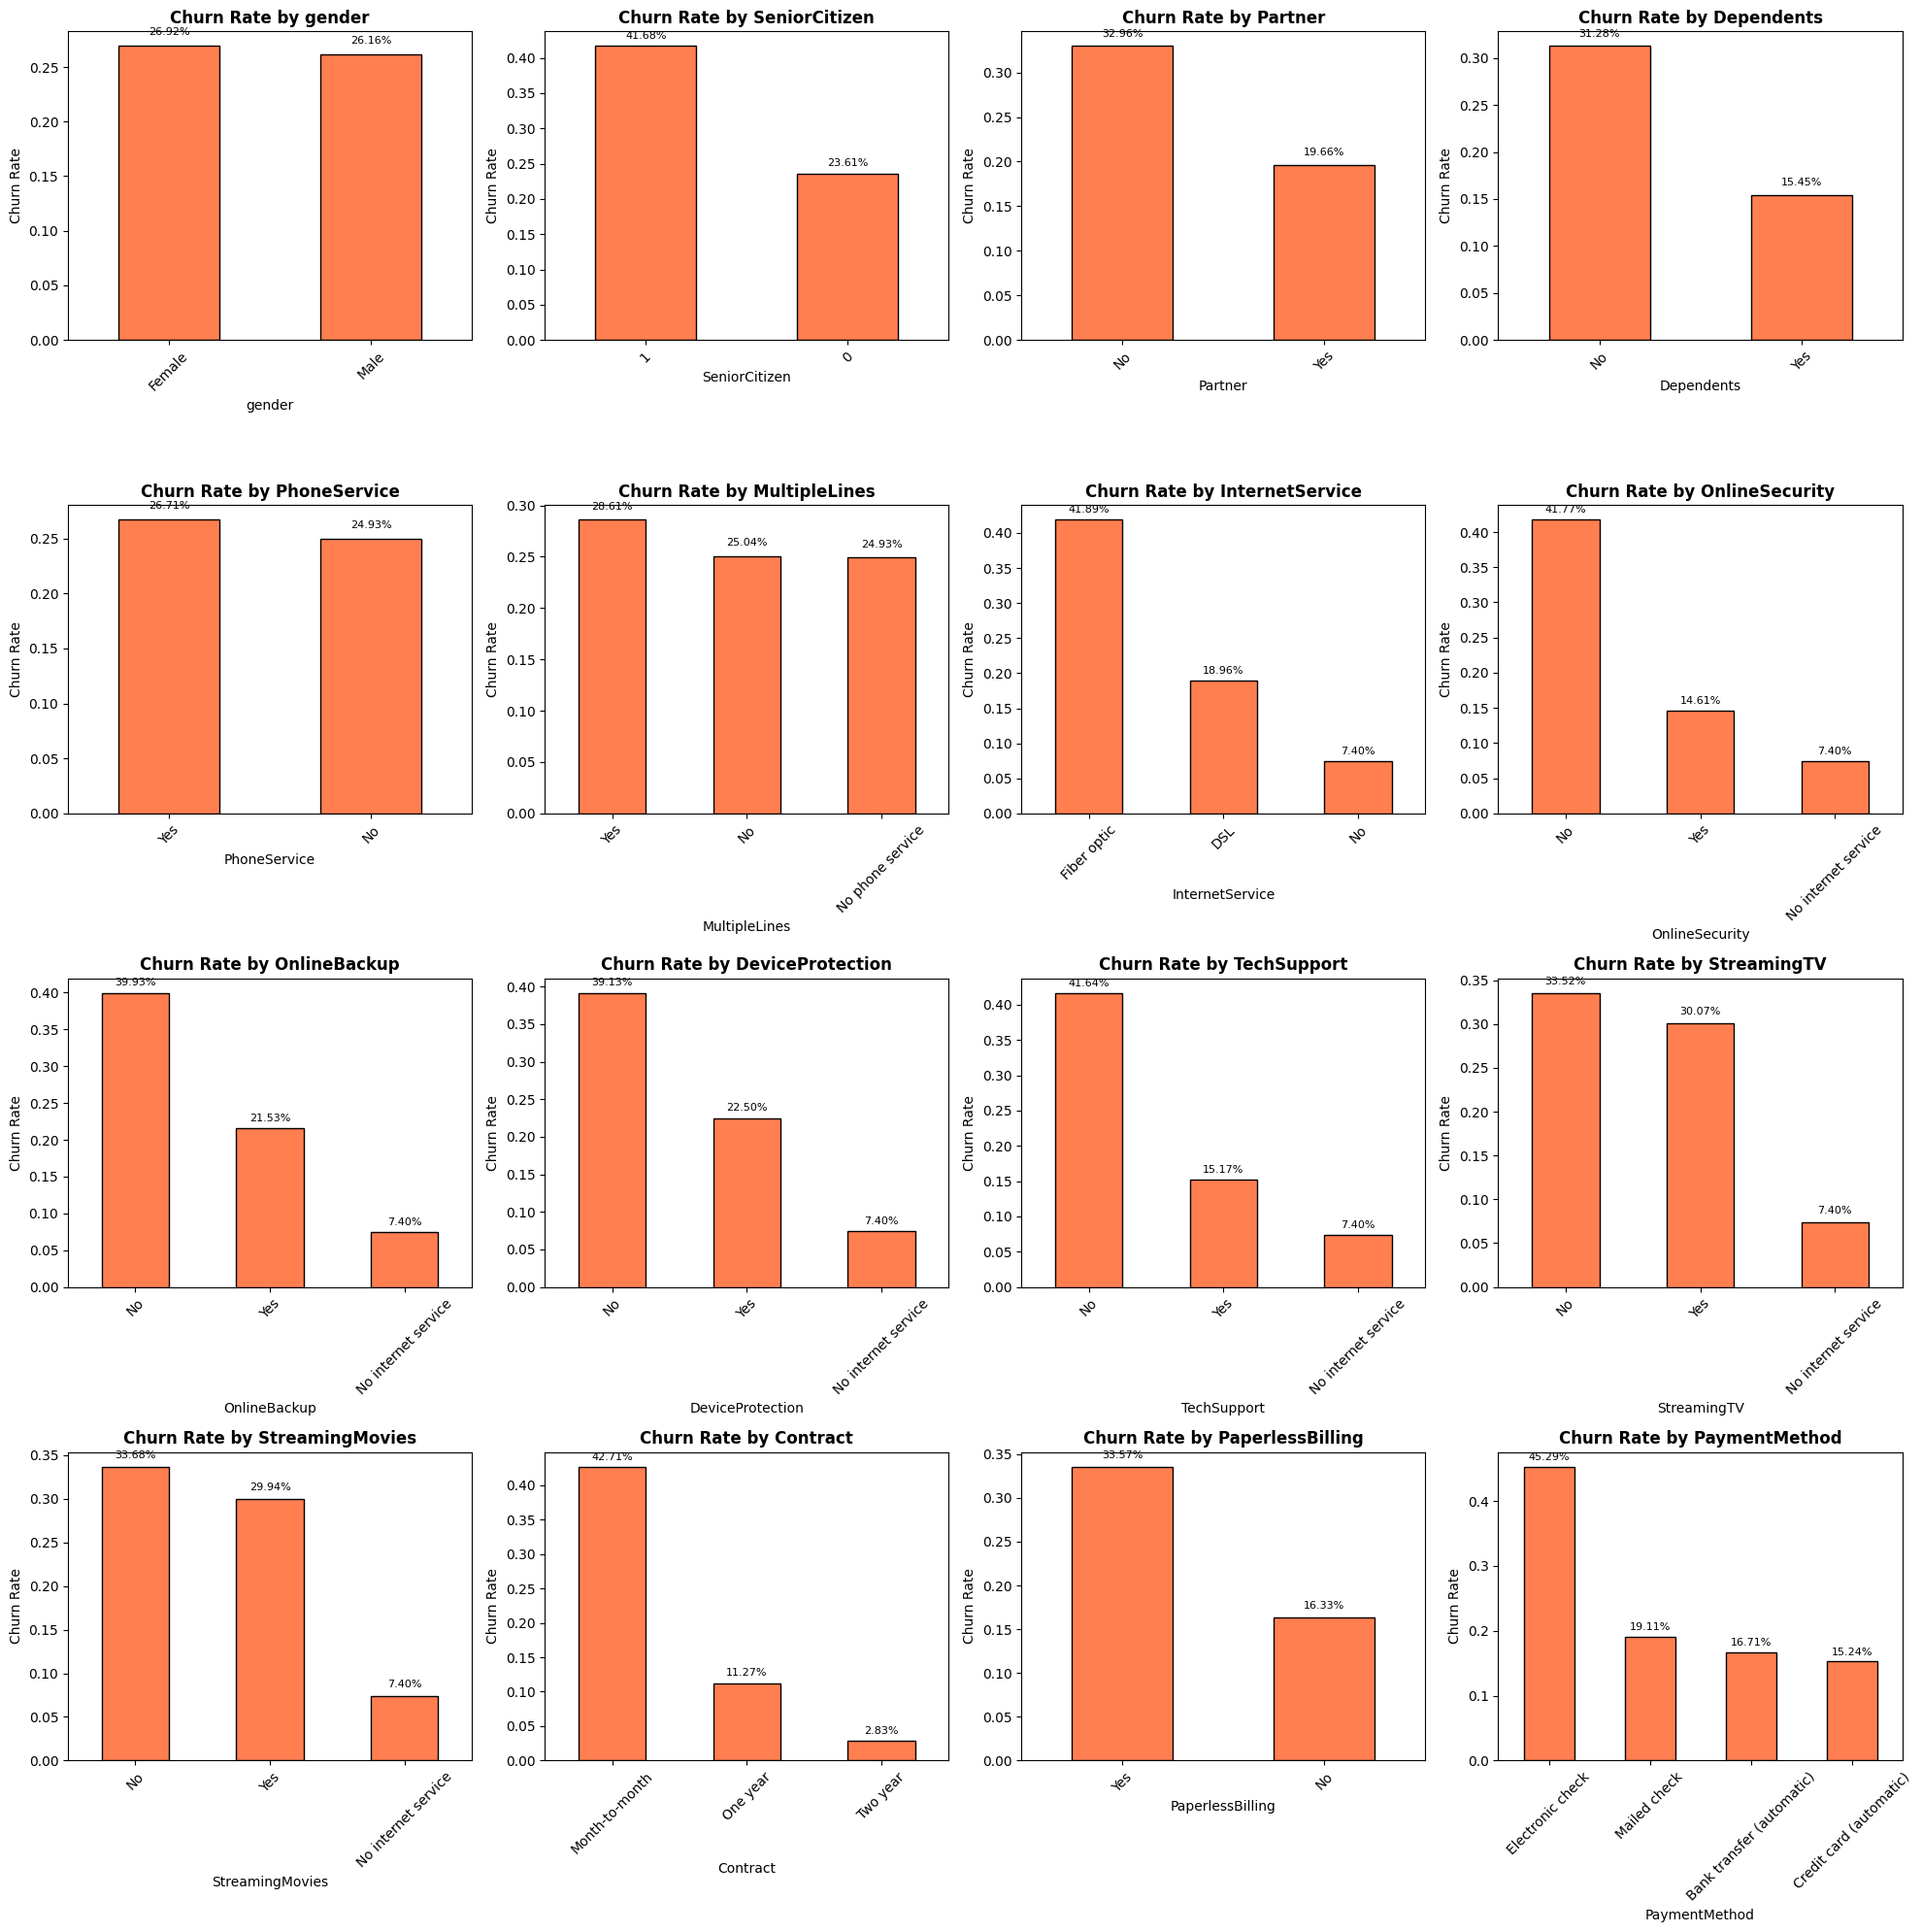

In [ ]:
# Cell 5: Advanced EDA - Categorical Features Analysis
print("\n5. Categorical Features vs Churn Analysis")

# Select categorical columns (excluding target)
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
            'Contract', 'PaperlessBilling', 'PaymentMethod']

# Create subplots for each categorical feature
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
axes = axes.ravel()

for idx, col in enumerate(cat_cols):
    # Calculate churn rate for each category
    churn_rates = df.groupby(col)['Churn'].mean().sort_values(ascending=False)

    # Create bar plot
    churn_rates.plot(kind='bar', ax=axes[idx], color='coral', edgecolor='black')
    axes[idx].set_title(f'Churn Rate by {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Churn Rate')
    axes[idx].tick_params(axis='x', rotation=45)

    # Add value labels on bars
    for i, v in enumerate(churn_rates.values):
        axes[idx].text(i, v + 0.01, f'{v:.2%}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()


6. Numerical Features Distribution


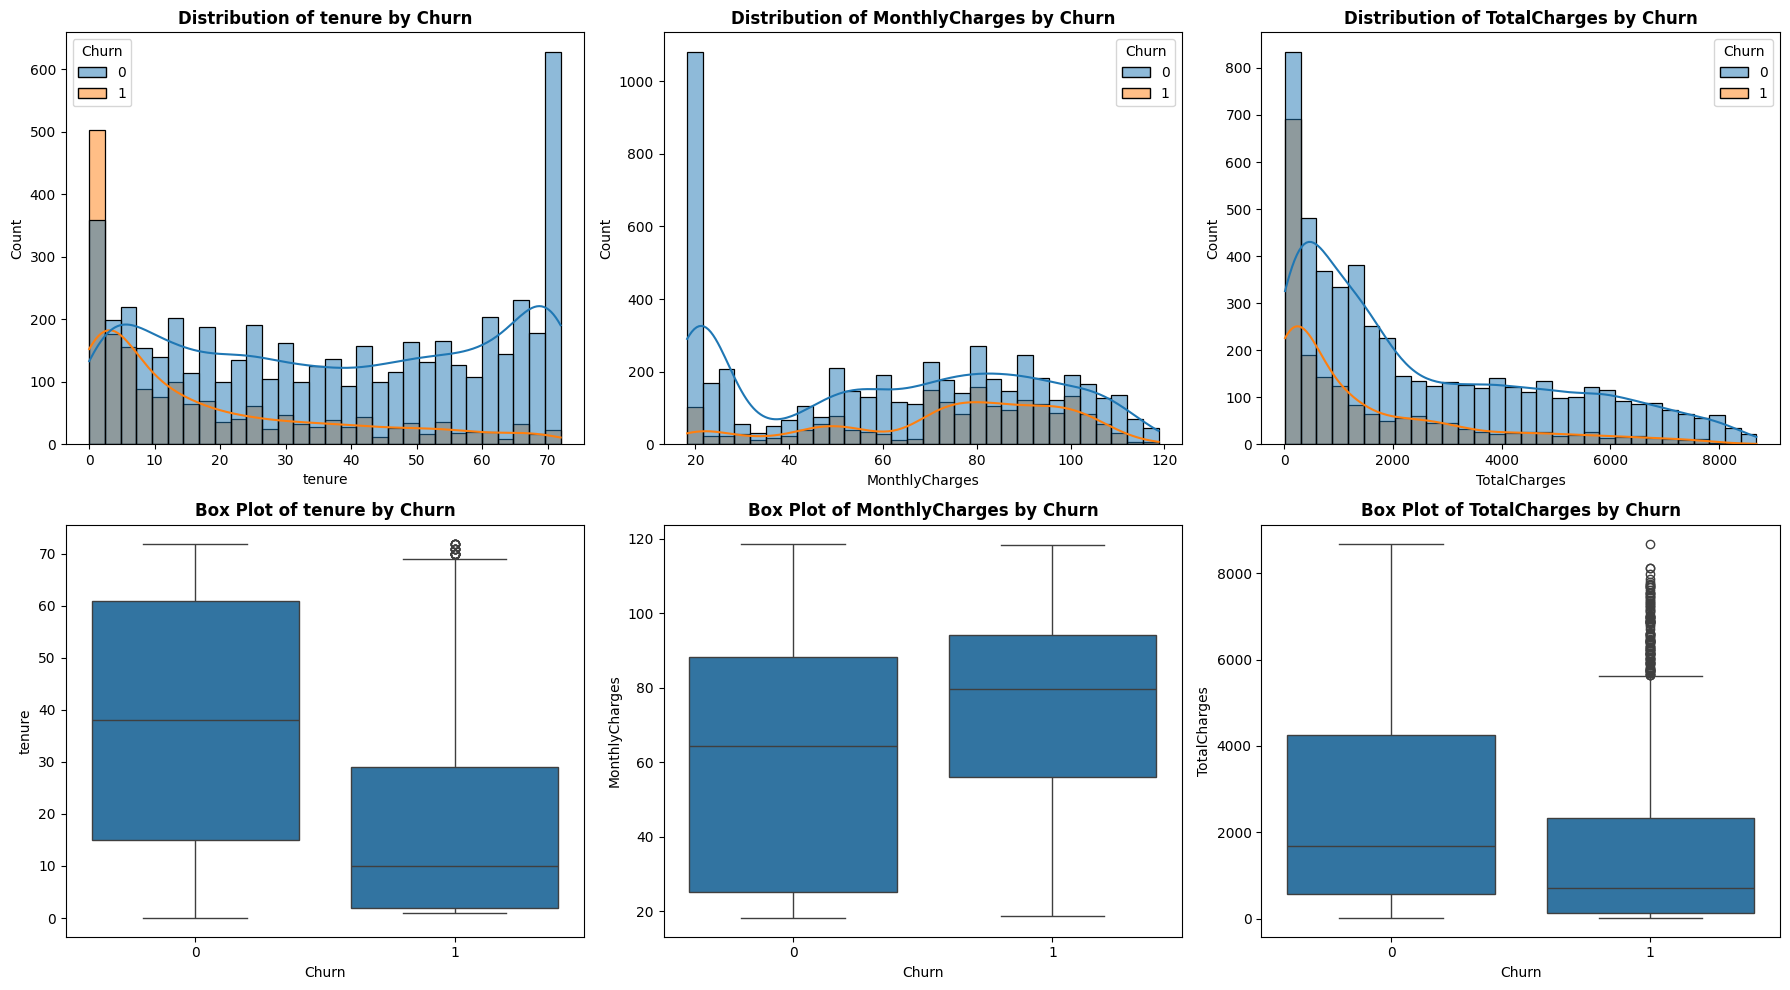


7. Correlation Matrix


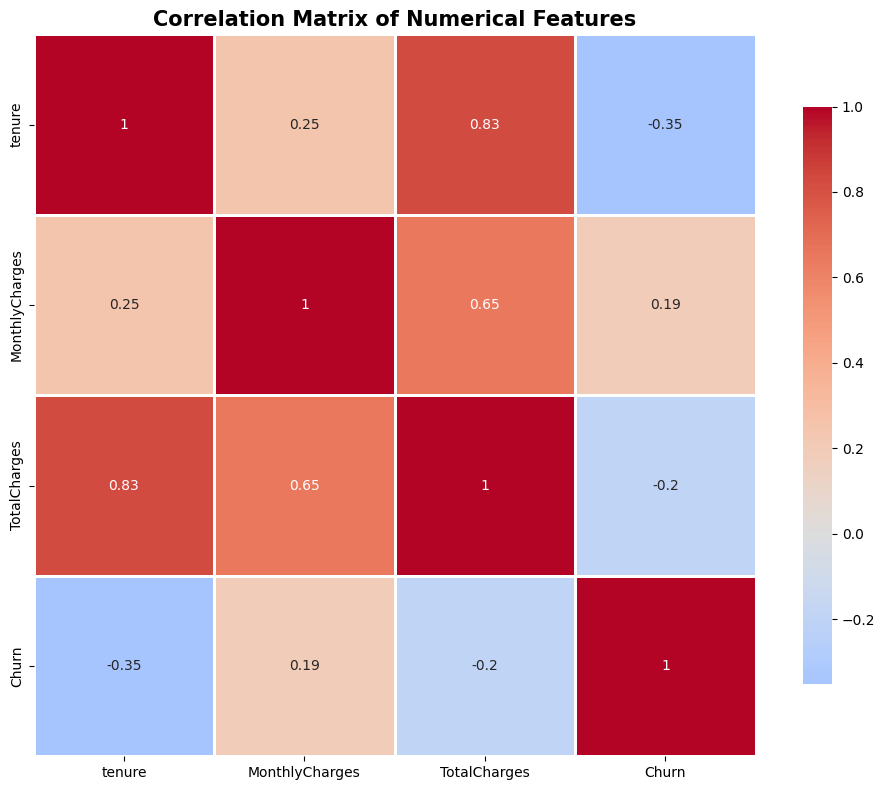

In [ ]:
# Cell 6: Numerical Features Analysis
print("\n6. Numerical Features Distribution")

# Select numerical columns
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for idx, col in enumerate(num_cols):
    # Distribution plot
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=axes[0, idx], bins=30)
    axes[0, idx].set_title(f'Distribution of {col} by Churn', fontweight='bold')

    # Box plot
    sns.boxplot(data=df, y=col, x='Churn', ax=axes[1, idx])
    axes[1, idx].set_title(f'Box Plot of {col} by Churn', fontweight='bold')

plt.tight_layout()
plt.show()

# Correlation matrix
print("\n7. Correlation Matrix")
numerical_df = df[num_cols + ['Churn']]

plt.figure(figsize=(10, 8))
correlation_matrix = numerical_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Numerical Features', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Cell 7: Feature Engineering
print("FEATURE ENGINEERING & PREPROCESSING")
print("="*50)

# Create a copy for preprocessing
df_processed = df.copy()

# 1. Create tenure groups
df_processed['tenure_group'] = pd.cut(df_processed['tenure'],
                                       bins=[0, 12, 24, 48, 60, 100],
                                       labels=['0-12', '12-24', '24-48', '48-60', '60+'])

# 2. Create average monthly charge
df_processed['AvgMonthlyCharges'] = df_processed['TotalCharges'] / (df_processed['tenure'] + 1)

# 3. Create charge per tenure ratio
df_processed['ChargeTenureRatio'] = df_processed['MonthlyCharges'] / (df_processed['tenure'] + 1)

# 4. Service count feature
service_cols = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df_processed['ServiceCount'] = 0
for col in service_cols:
    df_processed['ServiceCount'] += (df_processed[col] != 'No').astype(int)

print("New features created:")
print("- tenure_group: Categorical grouping of tenure")
print("- AvgMonthlyCharges: Average monthly charges")
print("- ChargeTenureRatio: Ratio of monthly charges to tenure")
print("- ServiceCount: Total number of services subscribed")

FEATURE ENGINEERING & PREPROCESSING
New features created:
- tenure_group: Categorical grouping of tenure
- AvgMonthlyCharges: Average monthly charges
- ChargeTenureRatio: Ratio of monthly charges to tenure
- ServiceCount: Total number of services subscribed


In [ ]:
# Cell 8: Encode Categorical Variables
# Identify categorical columns
categorical_columns = df_processed.select_dtypes(include=['object', 'category']).columns
categorical_columns = [col for col in categorical_columns if col != 'Churn']

print(f"Categorical columns to encode: {len(categorical_columns)}")


# One-hot encoding for categorical variables
df_encoded = pd.get_dummies(df_processed, columns=categorical_columns, drop_first=True)

print(f"\nShape before encoding: {df_processed.shape}")
print(f"Shape after encoding: {df_encoded.shape}")

# Separate features and target
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
print(f"Churn rate in dataset: {y.mean()*100:.2f}%")

Categorical columns to encode: 16

Shape before encoding: (7043, 24)
Shape after encoding: (7043, 38)

Feature matrix shape: (7043, 37)
Target vector shape: (7043,)
Churn rate in dataset: 26.54%


In [ ]:
# Cell 9: Train-Test Split and Handling Imbalanced Data
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)

print("Data Split Results:")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Training set churn rate: {y_train.mean()*100:.2f}%")
print(f"Testing set churn rate: {y_test.mean()*100:.2f}%")

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Handle imbalanced data using SMOTE
print("\nApplying SMOTE for handling class imbalance...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training set class distribution:")
print(f"Class 0: {sum(y_train == 0)}")
print(f"Class 1: {sum(y_train == 1)}")
print(f"\nAfter SMOTE - Resampled training set class distribution:")
print(f"Class 0: {sum(y_train_resampled == 0)}")
print(f"Class 1: {sum(y_train_resampled == 1)}")

Data Split Results:
Training set shape: (5634, 37)
Testing set shape: (1409, 37)
Training set churn rate: 26.54%
Testing set churn rate: 26.54%

Applying SMOTE for handling class imbalance...
Original training set class distribution:
Class 0: 4139
Class 1: 1495

After SMOTE - Resampled training set class distribution:
Class 0: 4139
Class 1: 4139


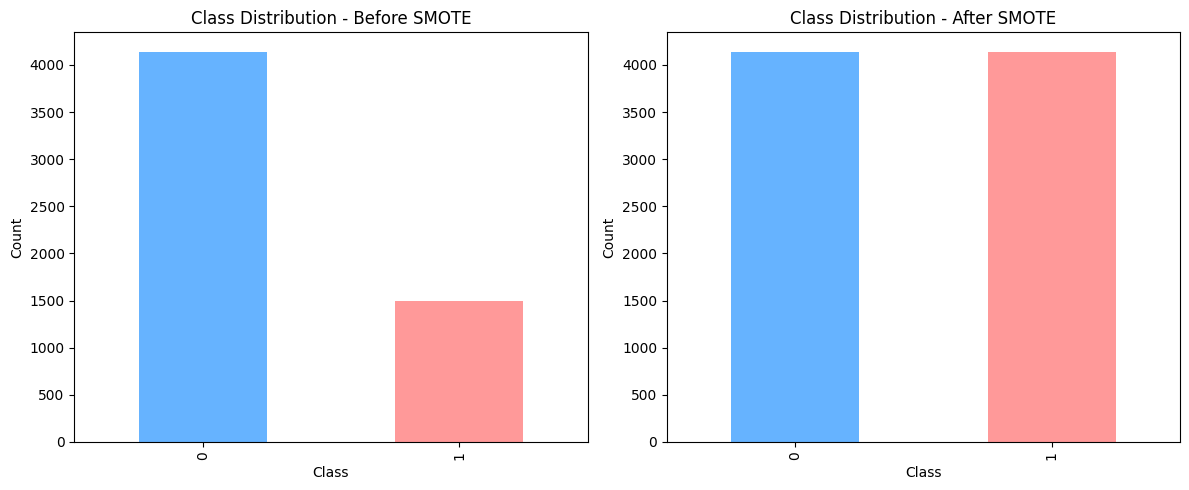

In [ ]:
# Cell 10: Visualize SMOTE effect
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
pd.Series(y_train).value_counts().plot(kind='bar', ax=axes[0], color=['#66b3ff', '#ff9999'])
axes[0].set_title('Class Distribution - Before SMOTE')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')

# After SMOTE
pd.Series(y_train_resampled).value_counts().plot(kind='bar', ax=axes[1], color=['#66b3ff', '#ff9999'])
axes[1].set_title('Class Distribution - After SMOTE')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
# Cell 11: Train Multiple ML Models
print("MACHINE LEARNING MODELS TRAINING")
print("="*50)

# Dictionary to store model performance
model_performance = {}
models = {}

# 1. Logistic Regression
print("\n1. Training Logistic Regression...")
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_resampled, y_train_resampled)
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

models['Logistic Regression'] = lr_model
model_performance['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1-Score': f1_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_lr)
}
print(f"Logistic Regression - Accuracy: {model_performance['Logistic Regression']['Accuracy']:.4f}, "
      f"F1-Score: {model_performance['Logistic Regression']['F1-Score']:.4f}")

# 2. Random Forest
print("\n2. Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

models['Random Forest'] = rf_model
model_performance['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_rf)
}
print(f"Random Forest - Accuracy: {model_performance['Random Forest']['Accuracy']:.4f}, "
      f"F1-Score: {model_performance['Random Forest']['F1-Score']:.4f}")

# 3. XGBoost
print("\n3. Training XGBoost...")
xgb_model = XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train_resampled, y_train_resampled)
y_pred_xgb = xgb_model.predict(X_test_scaled)
y_pred_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

models['XGBoost'] = xgb_model
model_performance['XGBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb),
    'Recall': recall_score(y_test, y_pred_xgb),
    'F1-Score': f1_score(y_test, y_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_xgb)
}
print(f"XGBoost - Accuracy: {model_performance['XGBoost']['Accuracy']:.4f}, "
      f"F1-Score: {model_performance['XGBoost']['F1-Score']:.4f}")

# 4. Gradient Boosting
print("\n4. Training Gradient Boosting...")
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model.fit(X_train_resampled, y_train_resampled)
y_pred_gb = gb_model.predict(X_test_scaled)
y_pred_proba_gb = gb_model.predict_proba(X_test_scaled)[:, 1]

models['Gradient Boosting'] = gb_model
model_performance['Gradient Boosting'] = {
    'Accuracy': accuracy_score(y_test, y_pred_gb),
    'Precision': precision_score(y_test, y_pred_gb),
    'Recall': recall_score(y_test, y_pred_gb),
    'F1-Score': f1_score(y_test, y_pred_gb),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_gb)
}
print(f"Gradient Boosting - Accuracy: {model_performance['Gradient Boosting']['Accuracy']:.4f}, "
      f"F1-Score: {model_performance['Gradient Boosting']['F1-Score']:.4f}")

MACHINE LEARNING MODELS TRAINING

1. Training Logistic Regression...
Logistic Regression - Accuracy: 0.7445, F1-Score: 0.6195

2. Training Random Forest...
Random Forest - Accuracy: 0.7715, F1-Score: 0.5718

3. Training XGBoost...
XGBoost - Accuracy: 0.7871, F1-Score: 0.5946

4. Training Gradient Boosting...
Gradient Boosting - Accuracy: 0.7722, F1-Score: 0.6052



MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.744500,0.512238,0.783422,0.619450,0.845393
Random Forest,0.771469,0.568783,0.574866,0.571809,0.821840
XGBoost,0.787083,0.601093,0.588235,0.594595,0.825609
Gradient Boosting,0.772179,0.560364,0.657754,0.605166,0.841837


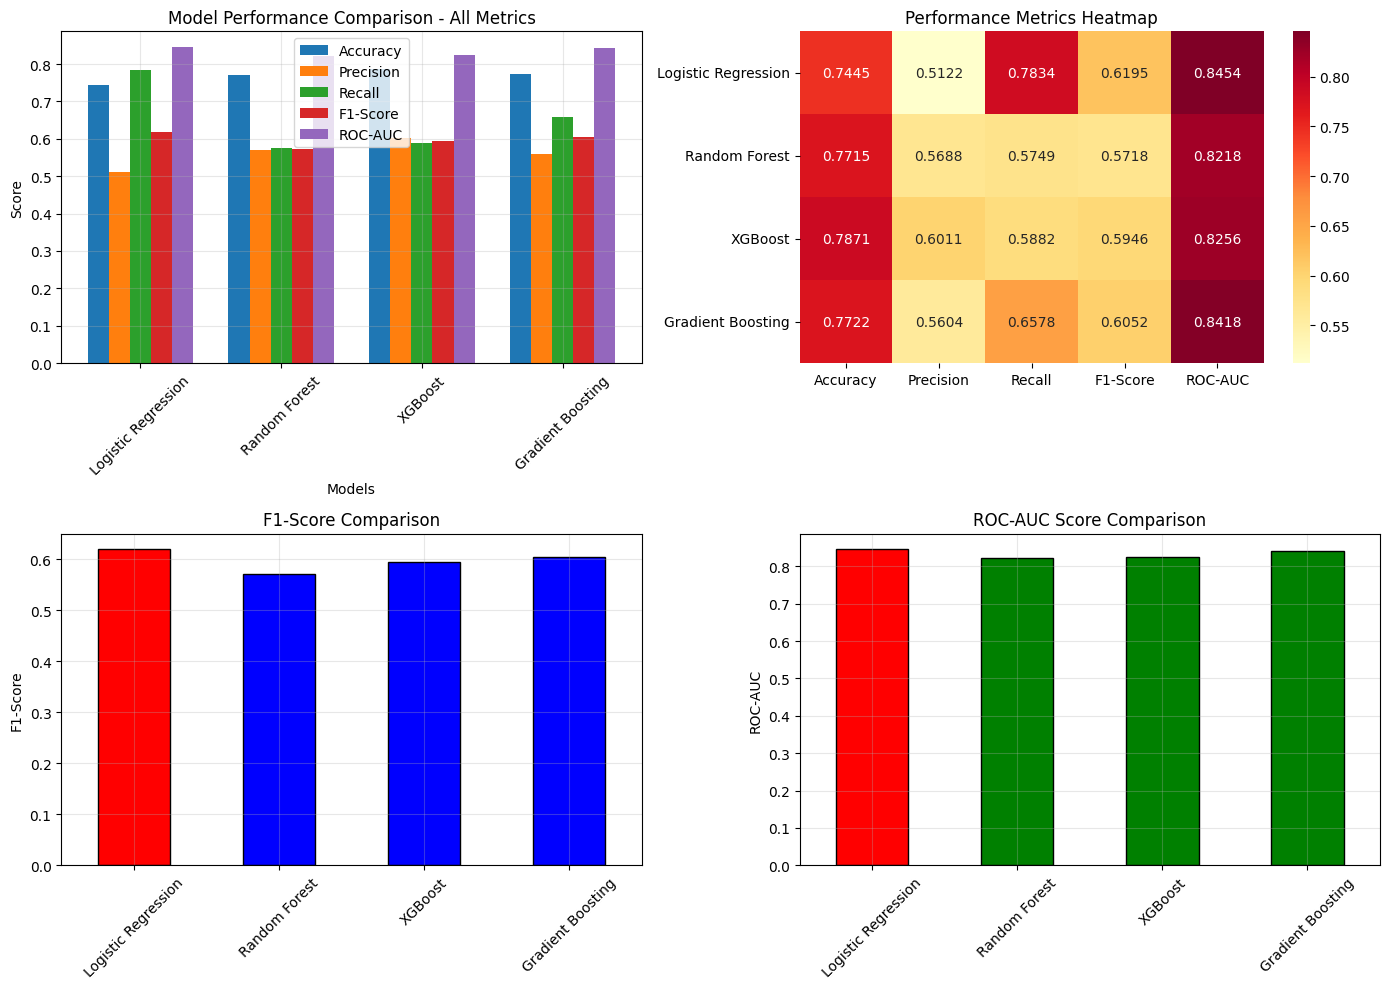


Best F1-Score: Logistic Regression - 0.6195
Best ROC-AUC: Logistic Regression - 0.8454


In [ ]:
# Cell 12: Model Performance Comparison
# Create performance dataframe
performance_df = pd.DataFrame(model_performance).T
print("\n" + "="*50)
print("MODEL PERFORMANCE COMPARISON")
print("="*50)
display(performance_df.style.background_gradient(cmap='Blues'))

# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Bar plot for all metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(performance_df.index))
width = 0.15

for i, metric in enumerate(metrics):
    bars = axes[0, 0].bar(x + i*width, performance_df[metric], width, label=metric)

axes[0, 0].set_xlabel('Models')
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_title('Model Performance Comparison - All Metrics')
axes[0, 0].set_xticks(x + width * 2)
axes[0, 0].set_xticklabels(performance_df.index, rotation=45)
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Heatmap
sns.heatmap(performance_df, annot=True, fmt='.4f', cmap='YlOrRd', ax=axes[0, 1])
axes[0, 1].set_title('Performance Metrics Heatmap')

# F1-Score comparison
best_f1 = performance_df['F1-Score'].idxmax()
colors = ['red' if model == best_f1 else 'blue' for model in performance_df.index]
performance_df['F1-Score'].plot(kind='bar', ax=axes[1, 0], color=colors, edgecolor='black')
axes[1, 0].set_title('F1-Score Comparison')
axes[1, 0].set_ylabel('F1-Score')
axes[1, 0].set_xticklabels(performance_df.index, rotation=45)
axes[1, 0].grid(True, alpha=0.3)

# ROC-AUC comparison
best_auc = performance_df['ROC-AUC'].idxmax()
colors = ['red' if model == best_auc else 'green' for model in performance_df.index]
performance_df['ROC-AUC'].plot(kind='bar', ax=axes[1, 1], color=colors, edgecolor='black')
axes[1, 1].set_title('ROC-AUC Score Comparison')
axes[1, 1].set_ylabel('ROC-AUC')
axes[1, 1].set_xticklabels(performance_df.index, rotation=45)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nBest F1-Score: {best_f1} - {performance_df.loc[best_f1, 'F1-Score']:.4f}")
print(f"Best ROC-AUC: {best_auc} - {performance_df.loc[best_auc, 'ROC-AUC']:.4f}")

In [ ]:
# Cell 13: Build and Train Deep Learning Model
print("DEEP LEARNING MODEL")
print("="*50)

# Build the model
def create_dl_model(input_dim):
    model = Sequential([
        # Input layer
        Dense(128, activation='relu', input_dim=input_dim, kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.3),

        # Hidden layer 1
        Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.3),

        # Hidden layer 2
        Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.2),

        # Hidden layer 3
        Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.2),

        # Output layer
        Dense(1, activation='sigmoid')
    ])

    return model

# Create model
dl_model = create_dl_model(X_train_resampled.shape[1])

# Compile
dl_model.compile(optimizer=Adam(learning_rate=0.001),
                 loss='binary_crossentropy',
                 metrics=['accuracy', tf.keras.metrics.Precision(),
                         tf.keras.metrics.Recall(), tf.keras.metrics.AUC()])

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.00001, verbose=1)

# Display model architecture
print("Model Architecture:")
dl_model.summary()

DEEP LEARNING MODEL
Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,641 (65.00 KB)

 Trainable params: 16,193 (63.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Cell 14: Train DL Model
print("\nTraining Deep Learning Model...")
history = dl_model.fit(
    X_train_resampled, y_train_resampled,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# Evaluate on test set
dl_evaluation = dl_model.evaluate(X_test_scaled, y_test, verbose=0)
dl_metrics = dict(zip(['loss', 'accuracy', 'precision', 'recall', 'auc'], dl_evaluation))

# Predictions
y_pred_dl_proba = dl_model.predict(X_test_scaled)
y_pred_dl = (y_pred_dl_proba > 0.5).astype(int)

# Calculate metrics
dl_f1 = f1_score(y_test, y_pred_dl)
dl_roc_auc = roc_auc_score(y_test, y_pred_dl_proba)

print(f"\nDeep Learning Model Performance:")
print(f"Accuracy: {dl_metrics['accuracy']:.4f}")
print(f"Precision: {dl_metrics['precision']:.4f}")
print(f"Recall: {dl_metrics['recall']:.4f}")
print(f"F1-Score: {dl_f1:.4f}")
print(f"ROC-AUC: {dl_roc_auc:.4f}")

# Add to performance dataframe
performance_df.loc['Deep Learning'] = {
    'Accuracy': dl_metrics['accuracy'],
    'Precision': dl_metrics['precision'],
    'Recall': dl_metrics['recall'],
    'F1-Score': dl_f1,
    'ROC-AUC': dl_roc_auc
}


Training Deep Learning Model...
Epoch 1/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.6755 - auc: 0.7357 - loss: 0.8090 - precision: 0.5556 - recall: 0.6722 - val_accuracy: 0.7627 - val_auc: 0.0000e+00 - val_loss: 0.7586 - val_precision: 1.0000 - val_recall: 0.7627 - learning_rate: 0.0010
Epoch 2/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7493 - auc: 0.8156 - loss: 0.6985 - precision: 0.6694 - recall: 0.6549 - val_accuracy: 0.7729 - val_auc: 0.0000e+00 - val_loss: 0.7253 - val_precision: 1.0000 - val_recall: 0.7729 - learning_rate: 0.0010
Epoch 3/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7600 - auc: 0.8267 - loss: 0.6748 - precision: 0.6817 - recall: 0.6754 - val_accuracy: 0.7488 - val_auc: 0.0000e+00 - val_loss: 0.7470 - val_precision: 1.0000 - val_recall: 0.7488 - learning_rate: 0.0010
Epoch 4/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7744 - auc: 0.8407 - loss: 0.6431 - precision: 0.7065 - recall: 0.6814 - val_accuracy

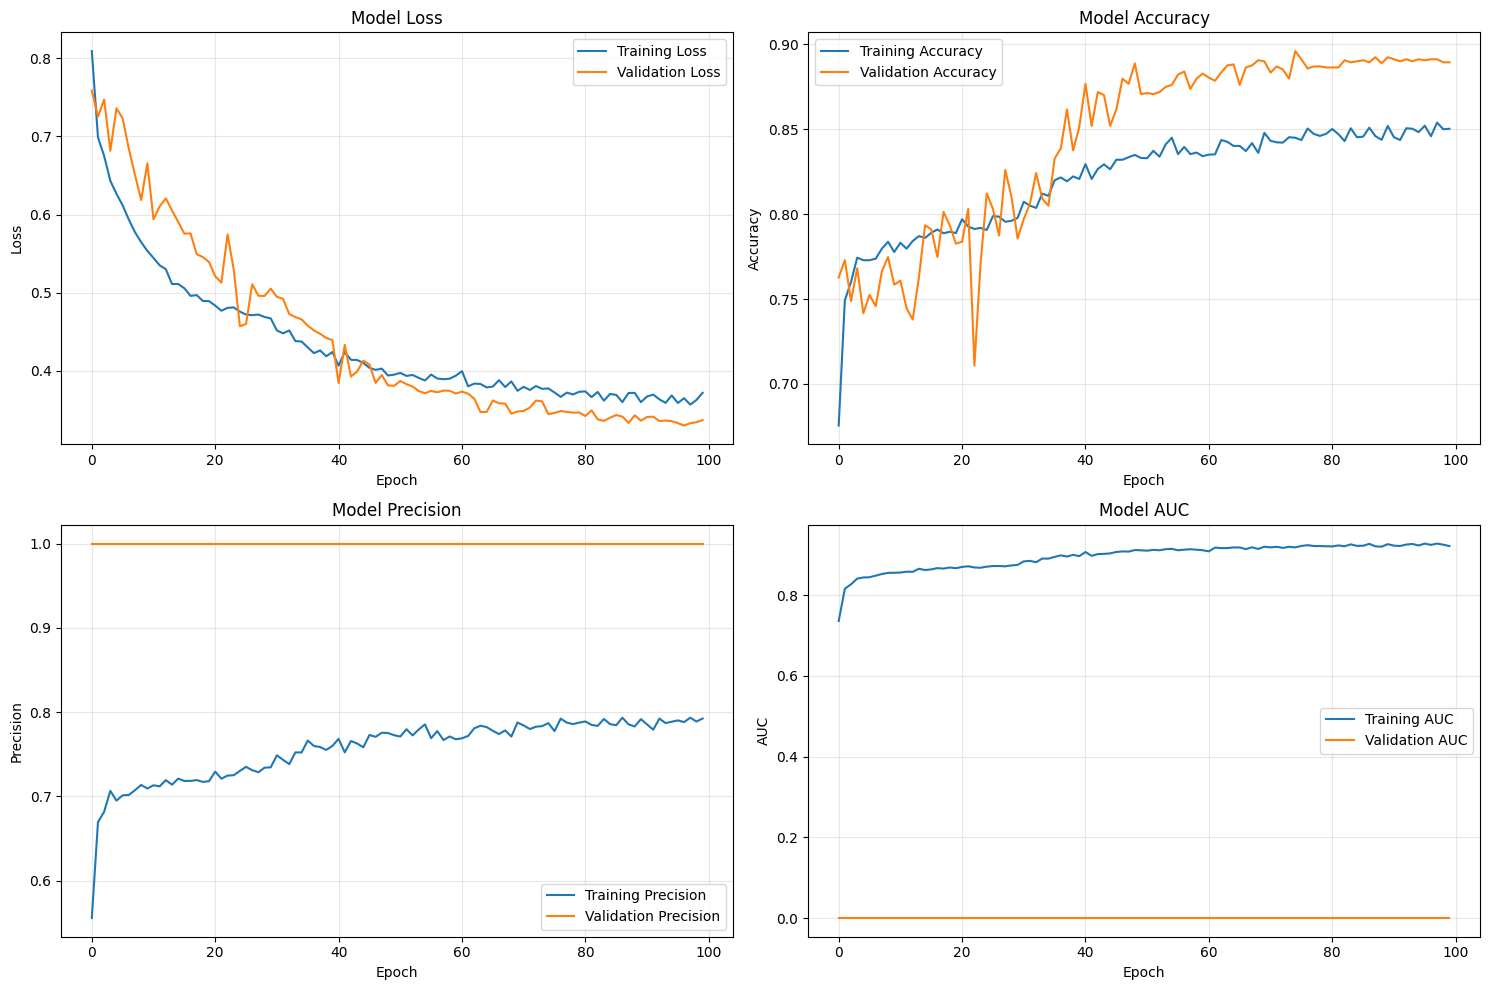

In [ ]:
# Cell 15: Plot Training History
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(history.history['loss'], label='Training Loss')
axes[0, 0].plot(history.history['val_loss'], label='Validation Loss')
axes[0, 0].set_title('Model Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history.history['accuracy'], label='Training Accuracy')
axes[0, 1].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0, 1].set_title('Model Accuracy')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision
axes[1, 0].plot(history.history['precision'], label='Training Precision')
axes[1, 0].plot(history.history['val_precision'], label='Validation Precision')
axes[1, 0].set_title('Model Precision')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# AUC
axes[1, 1].plot(history.history['auc'], label='Training AUC')
axes[1, 1].plot(history.history['val_auc'], label='Validation AUC')
axes[1, 1].set_title('Model AUC')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('AUC')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

CONFUSION MATRICES AND CLASSIFICATION REPORTS
Best Model based on F1-Score: Logistic Regression


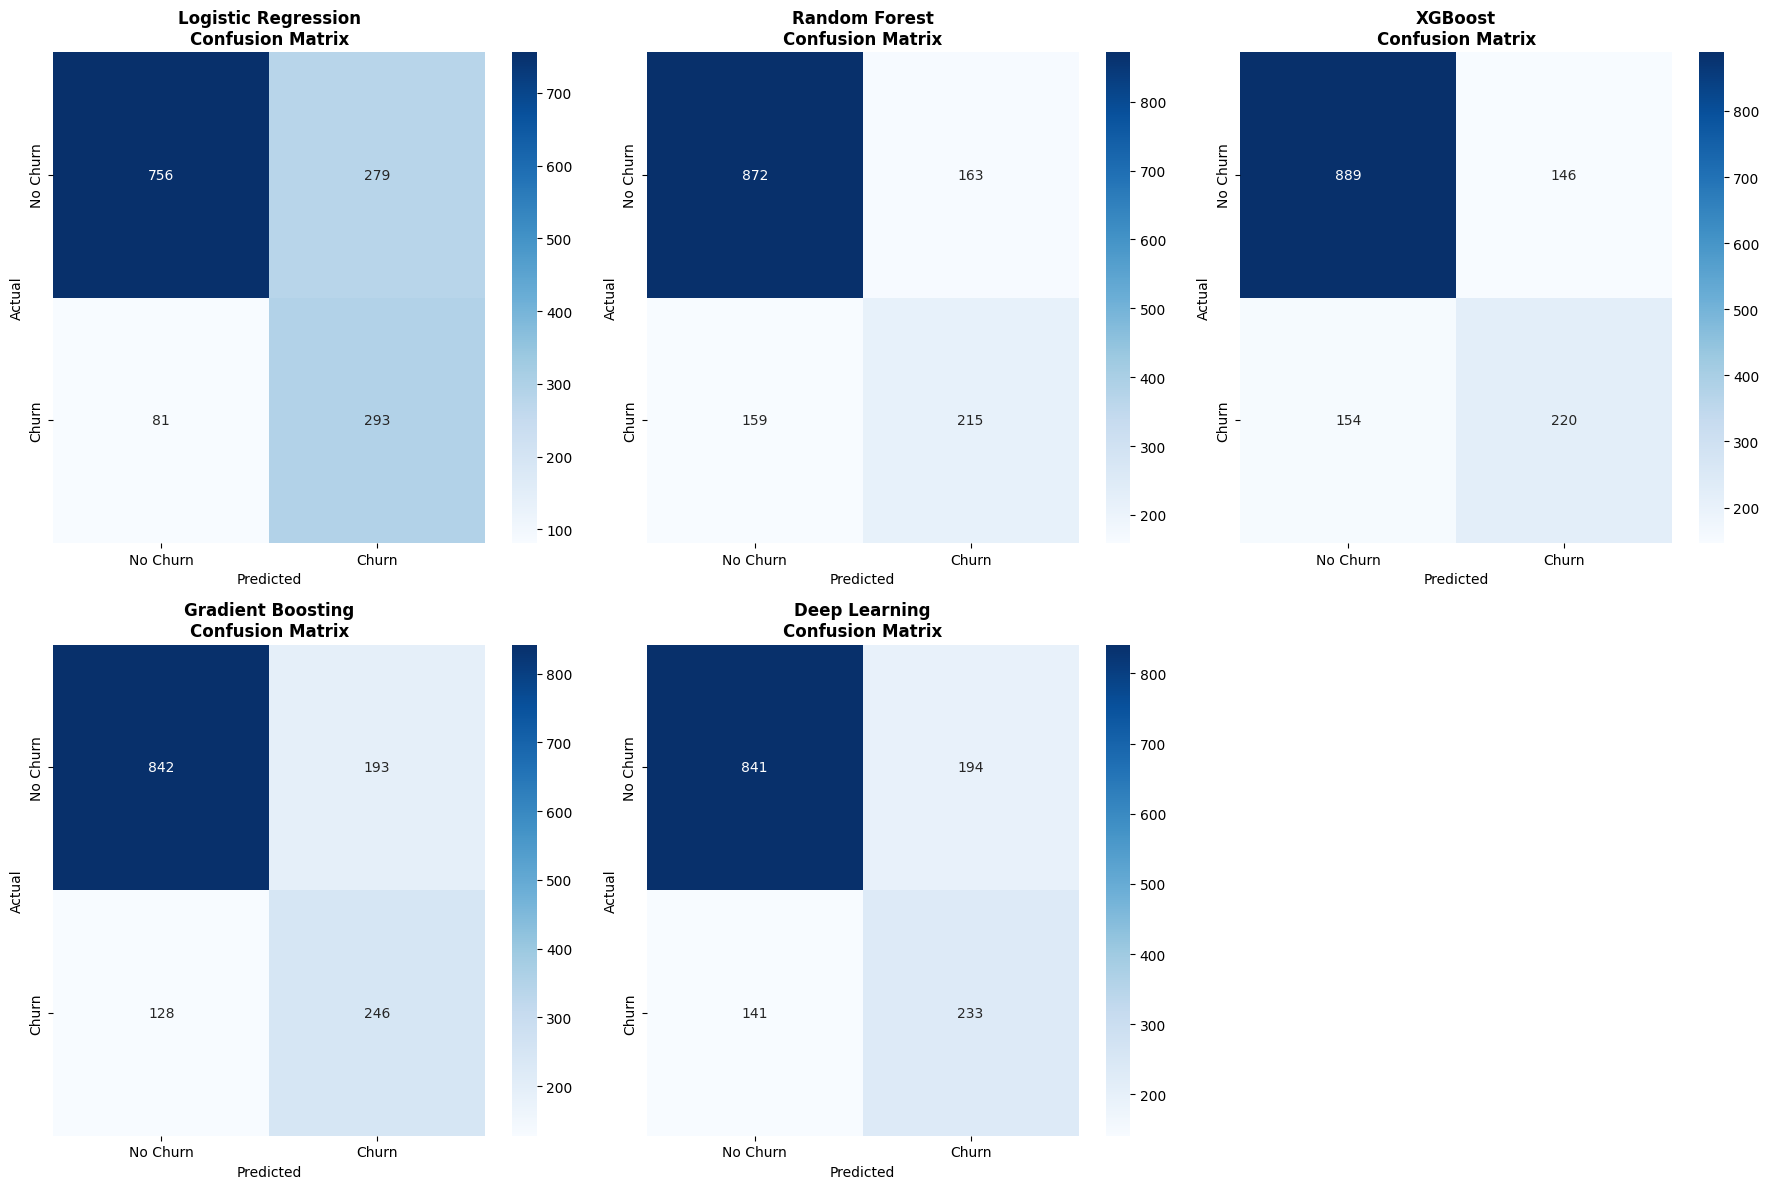

In [ ]:
# Cell 16: Confusion Matrices for All Models
print("CONFUSION MATRICES AND CLASSIFICATION REPORTS")
print("="*50)

# Get best model
best_model_name = performance_df['F1-Score'].idxmax()
print(f"Best Model based on F1-Score: {best_model_name}")

# Create confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

predictions_dict = {
    'Logistic Regression': y_pred_lr,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'Gradient Boosting': y_pred_gb,
    'Deep Learning': y_pred_dl
}

for idx, (model_name, y_pred) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'])
    axes[idx].set_title(f'{model_name}\nConfusion Matrix', fontweight='bold')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_xlabel('Predicted')

# Remove the extra subplot
if len(predictions_dict) < len(axes):
    axes[-1].remove()

plt.tight_layout()
plt.show()

In [ ]:
# Cell 17: Classification Report for Best Model
print(f"\nClassification Report for {best_model_name}:")
print("="*50)

if best_model_name == 'Deep Learning':
    best_pred = y_pred_dl
elif best_model_name == 'Logistic Regression':
    best_pred = y_pred_lr
elif best_model_name == 'Random Forest':
    best_pred = y_pred_rf
elif best_model_name == 'XGBoost':
    best_pred = y_pred_xgb
else:
    best_pred = y_pred_gb

print(classification_report(y_test, best_pred, target_names=['No Churn', 'Churn']))


Classification Report for Logistic Regression:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



ROC CURVES COMPARISON


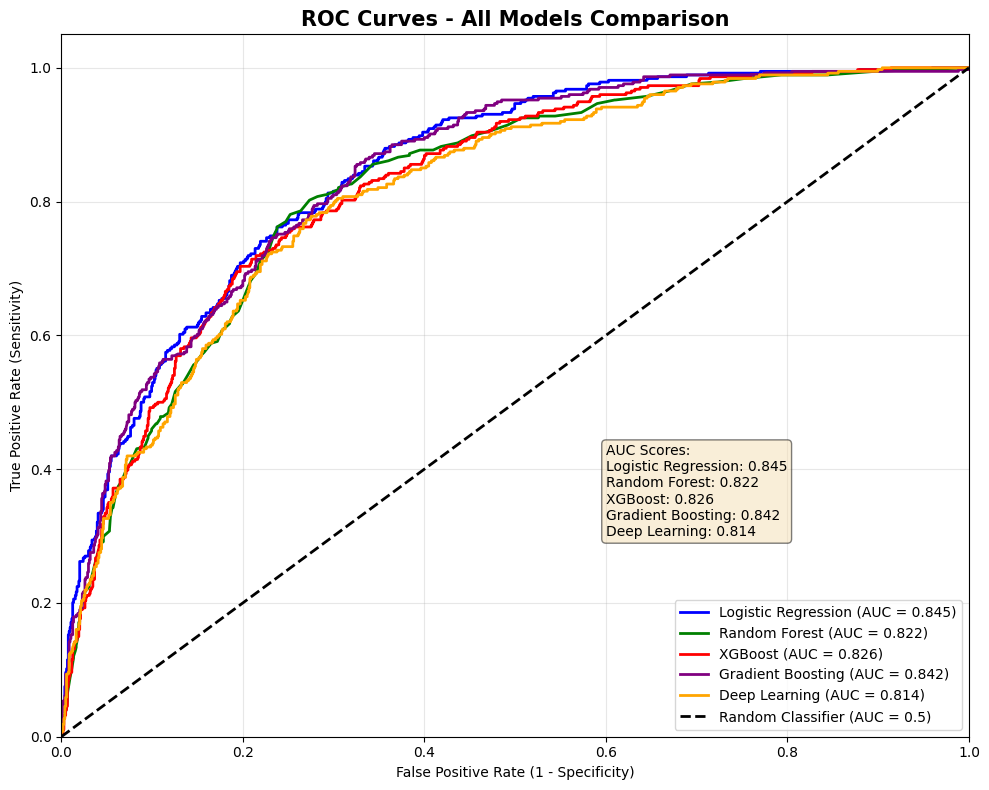

In [ ]:
# Cell 18: ROC Curves for All Models
print("ROC CURVES COMPARISON")
print("="*50)

# Calculate ROC curves
roc_data = {
    'Logistic Regression': (y_test, y_pred_proba_lr),
    'Random Forest': (y_test, y_pred_proba_rf),
    'XGBoost': (y_test, y_pred_proba_xgb),
    'Gradient Boosting': (y_test, y_pred_proba_gb),
    'Deep Learning': (y_test, y_pred_dl_proba)
}

plt.figure(figsize=(10, 8))

colors = ['blue', 'green', 'red', 'purple', 'orange']
for (model_name, (y_true, y_proba)), color in zip(roc_data.items(), colors):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{model_name} (AUC = {roc_auc:.3f})')

# Plot diagonal line
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier (AUC = 0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves - All Models Comparison', fontweight='bold', fontsize=15)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# Add AUC scores annotation
auc_scores = {name: roc_auc_score(y_test_true, y_pred_prob)
              for name, (y_test_true, y_pred_prob) in roc_data.items()}
plt.text(0.6, 0.3, 'AUC Scores:\n' + '\n'.join([f'{k}: {v:.3f}' for k, v in auc_scores.items()]),
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

PRECISION-RECALL CURVES


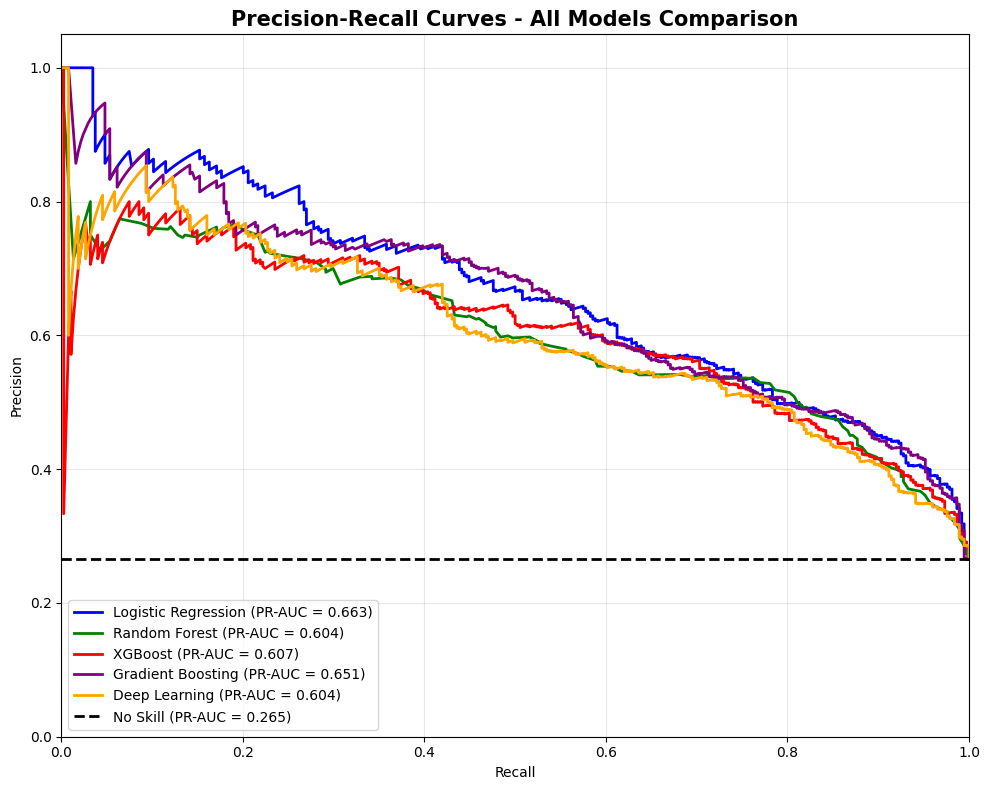

In [ ]:
# Cell 19: Precision-Recall Curves
print("PRECISION-RECALL CURVES")
print("="*50)

plt.figure(figsize=(10, 8))

for (model_name, (y_true, y_proba)), color in zip(roc_data.items(), colors):
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, color=color, lw=2,
             label=f'{model_name} (PR-AUC = {pr_auc:.3f})')

# No-skill line
no_skill = len(y_test[y_test == 1]) / len(y_test)
plt.plot([0, 1], [no_skill, no_skill], 'k--', lw=2, label=f'No Skill (PR-AUC = {no_skill:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves - All Models Comparison', fontweight='bold', fontsize=15)
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

FEATURE IMPORTANCE ANALYSIS


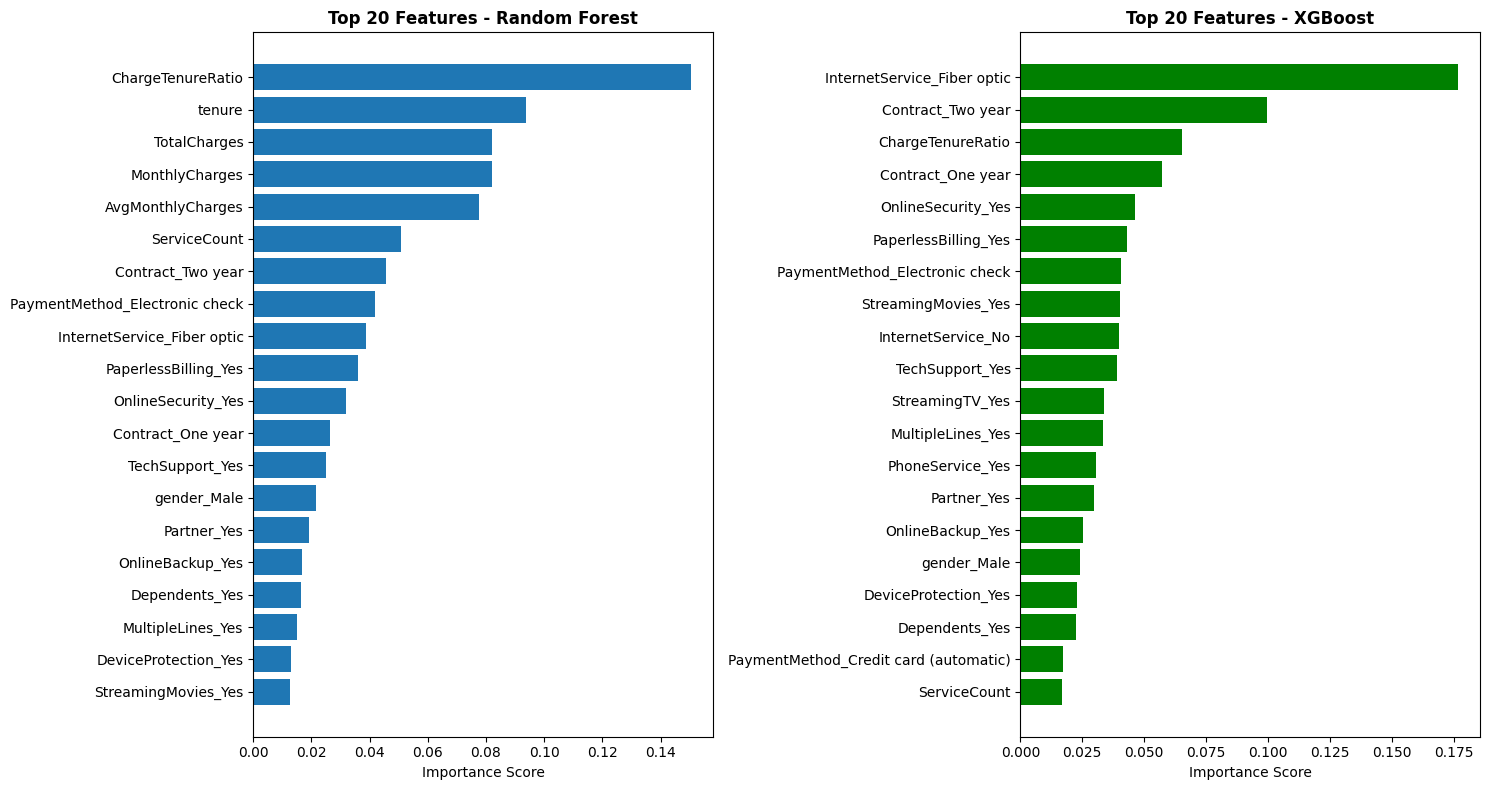

In [ ]:
# Cell 20: Feature Importance Analysis
print("FEATURE IMPORTANCE ANALYSIS")
print("="*50)

# Get feature importance from Random Forest and XGBoost
feature_names = X.columns

# Random Forest Feature Importance
rf_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

# XGBoost Feature Importance
xgb_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

# Plot feature importance
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Random Forest
axes[0].barh(range(len(rf_importance)), rf_importance['importance'].values)
axes[0].set_yticks(range(len(rf_importance)))
axes[0].set_yticklabels(rf_importance['feature'].values)
axes[0].set_xlabel('Importance Score')
axes[0].set_title('Top 20 Features - Random Forest', fontweight='bold')
axes[0].invert_yaxis()

# XGBoost
axes[1].barh(range(len(xgb_importance)), xgb_importance['importance'].values, color='green')
axes[1].set_yticks(range(len(xgb_importance)))
axes[1].set_yticklabels(xgb_importance['feature'].values)
axes[1].set_xlabel('Importance Score')
axes[1].set_title('Top 20 Features - XGBoost', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Cell 21: Cross-Validation Scores
print("CROSS-VALIDATION ANALYSIS")
print("="*50)

# Perform cross-validation on best model
from sklearn.model_selection import cross_validate

best_model = models.get(best_model_name)
if best_model_name != 'Deep Learning':
    cv_scores = cross_validate(best_model, X_train_scaled, y_train,
                                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                                scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])

    print(f"\nCross-Validation Results for {best_model_name}:")
    print(f"Accuracy: {cv_scores['test_accuracy'].mean():.4f} (+/- {cv_scores['test_accuracy'].std()*2:.4f})")
    print(f"Precision: {cv_scores['test_precision'].mean():.4f} (+/- {cv_scores['test_precision'].std()*2:.4f})")
    print(f"Recall: {cv_scores['test_recall'].mean():.4f} (+/- {cv_scores['test_recall'].std()*2:.4f})")
    print(f"F1-Score: {cv_scores['test_f1'].mean():.4f} (+/- {cv_scores['test_f1'].std()*2:.4f})")
    print(f"ROC-AUC: {cv_scores['test_roc_auc'].mean():.4f} (+/- {cv_scores['test_roc_auc'].std()*2:.4f})")

CROSS-VALIDATION ANALYSIS

Cross-Validation Results for Logistic Regression:
Accuracy: 0.8088 (+/- 0.0163)
Precision: 0.6812 (+/- 0.0466)
Recall: 0.5271 (+/- 0.0642)
F1-Score: 0.5936 (+/- 0.0441)
ROC-AUC: 0.8486 (+/- 0.0235)


In [ ]:
# Cell 22: Final Summary Dashboard
print("\n" + "="*60)
print("FINAL PROJECT SUMMARY")
print("="*60)

# Update final performance display
print("\n Final Model Performance Comparison:")
display(performance_df.style.background_gradient(cmap='RdYlGn', axis=0)
        .format("{:.4f}")
        .set_caption("All Models Performance Metrics"))

# Best model summary
best_f1_model = performance_df['F1-Score'].idxmax()
best_auc_model = performance_df['ROC-AUC'].idxmax()

print(f"\n Best Model by F1-Score: {best_f1_model} ({performance_df.loc[best_f1_model, 'F1-Score']:.4f})")
print(f" Best Model by ROC-AUC: {best_auc_model} ({performance_df.loc[best_auc_model, 'ROC-AUC']:.4f})")


FINAL PROJECT SUMMARY

 Final Model Performance Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7445,0.5122,0.7834,0.6195,0.8454
Random Forest,0.7715,0.5688,0.5749,0.5718,0.8218
XGBoost,0.7871,0.6011,0.5882,0.5946,0.8256
Gradient Boosting,0.7722,0.5604,0.6578,0.6052,0.8418
Deep Learning,0.7622,0.5457,0.6230,0.5818,0.8144



 Best Model by F1-Score: Logistic Regression (0.6195)
 Best Model by ROC-AUC: Logistic Regression (0.8454)
